<a href="https://colab.research.google.com/github/khansa-020/Breast_Lesion_segmentation/blob/main/02_preprocess_resize_split_DMID_(2).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DMID Breast Cancer Segmentation — Preprocessing: resize to 128×128 and split 70/20/10

Continues from `01_eda_DMID_BC_segmentation`. Output layout:

```
OUT_DIR/
  train/ images/  masks/  roi_masks/     (70%)
  test/  images/  masks/  roi_masks/     (20%)
  val/   images/  masks/  roi_masks/     (10%)
  split_manifest.csv
  preprocessing_report.csv
```
`masks/` = pixel-level lesion annotation (binary 0/255), `roi_masks/` = ROI mask (binary 0/255). All files are 128×128 8-bit PNG with the same base name (e.g. `IMG008.png`) in all three folders.

## 1. Setup

In [ ]:
!pip -q install tifffile imagecodecs   # imagecodecs is required to read the LZW-compressed DMID TIFFs

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
# Re-extract only if the runtime was reset since the EDA notebook:
!unzip -q "/content/drive/MyDrive/breast-cancer-segmentation/data/DMID.zip" -d /content/DMID

Mounted at /content/drive


In [ ]:
import re, hashlib, shutil
from pathlib import Path
import numpy as np, pandas as pd, cv2, tifffile
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

DATA_ROOT      = Path('/content/DMID')
IMAGE_DIR      = DATA_ROOT / 'TIFF Images' / 'TIFF Images'
PIXEL_MASK_DIR = DATA_ROOT / 'Pixel-level annotation' / 'Pixel-level annotation'
ROI_MASK_DIR   = DATA_ROOT / 'ROI Masks' / 'ROI Masks'

OUT_DIR  = Path('/content/DMID_128_2')                      # saved here, copied to Drive at the end
DRIVE_OUT = Path('/content/drive/MyDrive/breast-cancer-segmentation/data/DMID_128_2')

SIZE = 128
PAD_TO_SQUARE = True   # True: keep aspect ratio (pad black to square, then resize). False: stretch to 128x128.
SEED = 42
SPLIT = {'train': 0.70, 'test': 0.20, 'val': 0.10}

## 2. Build the image ↔ mask pairs

Only 269 of the 510 images have annotations, so only those can be used for supervised segmentation.

**Fix for the EDA duplicate step:** it kept `IMG279 - Copy.tif` and dropped `IMG279.tif`, so IMG279's mask no longer matched (you got 268 pairs instead of 269). Here the pair id strips ` - Copy`, and among duplicates the original name is kept.

In [ ]:
def list_tifs(folder):
    return sorted(p for p in folder.rglob('*') if p.is_file() and p.suffix.lower() in {'.tif', '.tiff'})

def pair_id(path):
    return re.sub(r'\s*-\s*copy.*$', '', path.stem, flags=re.I).strip().upper()

def read_raw(path):
    return np.asarray(tifffile.imread(str(path)))

def pixel_hash(path):
    a = np.ascontiguousarray(read_raw(path))
    return hashlib.sha256((str(a.shape) + str(a.dtype)).encode() + a.tobytes()).hexdigest()

# group image files by pair id; if a pair id has several files (copies), keep one
imgs_by_id = {}
for p in list_tifs(IMAGE_DIR):
    imgs_by_id.setdefault(pair_id(p), []).append(p)

image_by_id = {}
for k, files in imgs_by_id.items():
    if len(files) > 1:
        hashes = {pixel_hash(f) for f in files}
        print(f'{k}: {len(files)} files {[f.name for f in files]} -> identical pixels: {len(hashes) == 1}')
    # prefer the file without "Copy" in its name
    image_by_id[k] = sorted(files, key=lambda f: ('copy' in f.stem.lower(), f.name))[0]

pix_by_id = {pair_id(p): p for p in list_tifs(PIXEL_MASK_DIR)}
roi_by_id = {pair_id(p): p for p in list_tifs(ROI_MASK_DIR)}

ids = sorted(set(image_by_id) & set(pix_by_id) & set(roi_by_id))
print('images:', len(image_by_id), '| pixel masks:', len(pix_by_id), '| ROI masks:', len(roi_by_id))
print('complete pairs (image + annotation + ROI):', len(ids))
print('masks without image:', sorted((set(pix_by_id) | set(roi_by_id)) - set(image_by_id)))

IMG279: 2 files ['IMG279 - Copy.tif', 'IMG279.tif'] -> identical pixels: True
images: 510 | pixel masks: 269 | ROI masks: 269
complete pairs (image + annotation + ROI): 269
masks without image: []


## 3. Loading and resizing helpers

- **Image:** 4-channel (RGBA) / 3-channel / 1-channel TIFFs are all converted to one grayscale channel (alpha dropped).
- **Masks:** the pixel-level annotation is stored as 4-channel RGBA with ~230 intensity levels (not a clean 0/1 mask), so it is binarised: foreground = any RGB value > 0. ROI masks are already {0, 255}.
- **Resize:** image uses `INTER_AREA` (best for heavy downsampling, 6000 px → 128 px). Masks are shrunk as a float with `INTER_AREA` and re-thresholded at 0.5, which keeps small lesions better than nearest-neighbour.
- If an image and its mask differ in size by a few pixels (the EDA showed mask sizes can differ), the mask is first resized to the image size, so they stay aligned. Those cases are logged.

In [ ]:
def to_gray(arr):
    if arr.ndim == 2:
        return arr
    if arr.ndim == 3 and arr.shape[0] in (1, 3, 4) and arr.shape[-1] not in (1, 3, 4):
        arr = np.moveaxis(arr, 0, -1)
    if arr.shape[-1] == 1:
        return arr[..., 0]
    rgb = arr[..., :3]                       # drop alpha
    if np.array_equal(rgb[..., 0], rgb[..., 1]) and np.array_equal(rgb[..., 1], rgb[..., 2]):
        return rgb[..., 0]
    return cv2.cvtColor(np.ascontiguousarray(rgb), cv2.COLOR_RGB2GRAY)

def to_binary(arr):
    """any foreground value in the colour channels -> 1 (alpha ignored)"""
    if arr.ndim == 3:
        arr = arr[..., :3].max(axis=-1) if arr.shape[-1] >= 3 else arr.max(axis=-1)
    return (arr > 0).astype(np.uint8)

def pad_square(a):
    h, w = a.shape[:2]
    s = max(h, w)
    top, left = (s - h) // 2, (s - w) // 2
    return np.pad(a, ((top, s - h - top), (left, s - w - left)), mode='constant')

def resize_image(gray):
    if PAD_TO_SQUARE: gray = pad_square(gray)
    return cv2.resize(gray, (SIZE, SIZE), interpolation=cv2.INTER_AREA)

def resize_mask(binary):
    if PAD_TO_SQUARE: binary = pad_square(binary)
    small = cv2.resize(binary.astype(np.float32), (SIZE, SIZE), interpolation=cv2.INTER_AREA)
    return ((small >= 0.5).astype(np.uint8)) * 255

def process_pair(i):
    img  = to_gray(read_raw(image_by_id[i]))
    pix  = to_binary(read_raw(pix_by_id[i]))
    roi  = to_binary(read_raw(roi_by_id[i]))
    info = {'id': i, 'orig_h': img.shape[0], 'orig_w': img.shape[1]}
    for name, m in (('pix', pix), ('roi', roi)):
        info[f'{name}_size_mismatch'] = m.shape != img.shape
        if m.shape != img.shape:
            m = cv2.resize(m, (img.shape[1], img.shape[0]), interpolation=cv2.INTER_NEAREST)
            if name == 'pix': pix = m
            else: roi = m
    info['pix_area_frac_orig'] = float(pix.mean())
    info['roi_area_frac_orig'] = float(roi.mean())
    out = (resize_image(img), resize_mask(pix), resize_mask(roi))
    info['pix_area_frac_128'] = float((out[1] > 0).mean())
    info['roi_area_frac_128'] = float((out[2] > 0).mean())
    info['pix_empty_after_resize'] = info['pix_area_frac_orig'] > 0 and info['pix_area_frac_128'] == 0
    info['pix_empty_in_source'] = info['pix_area_frac_orig'] == 0
    info['roi_empty_after_resize'] = info['roi_area_frac_orig'] > 0 and info['roi_area_frac_128'] == 0
    return out, info

## 4. Split: 70% train / 20% test / 10% val

Stratified by annotation size (quartiles of lesion area) so each split has a similar mix of small and large lesions. Seed is fixed for reproducibility. The split is done on image ids, so each image and both of its masks always land in the same split.

In [ ]:
# first pass: process every pair in memory (128x128 is tiny), collecting stats
data, rows = {}, []
for n, i in enumerate(ids, 1):
    data[i], info = process_pair(i)
    rows.append(info)
    if n % 50 == 0: print(f'{n}/{len(ids)}')
report = pd.DataFrame(rows).set_index('id')

# stratification key: lesion-area quartile
strata = pd.qcut(report['pix_area_frac_orig'].rank(method='first'), 4, labels=False)

def split_ids(ids_, train_size, strat):
    try:
        return train_test_split(ids_, train_size=train_size, random_state=SEED, stratify=strat.loc[ids_])
    except ValueError as e:                       # a stratum is too small -> plain random split
        print('Stratification skipped:', e)
        return train_test_split(ids_, train_size=train_size, random_state=SEED)

train_ids, rest_ids = split_ids(ids, SPLIT['train'], strata)
test_ids, val_ids   = split_ids(rest_ids, SPLIT['test'] / (SPLIT['test'] + SPLIT['val']), strata)
splits = {'train': sorted(train_ids), 'test': sorted(test_ids), 'val': sorted(val_ids)}
print({k: len(v) for k, v in splits.items()}, '| total', sum(len(v) for v in splits.values()))
assert not (set(train_ids) & set(test_ids)) and not (set(train_ids) & set(val_ids)) and not (set(test_ids) & set(val_ids))

50/269
100/269
150/269
200/269
250/269
{'train': 188, 'test': 54, 'val': 27} | total 269


## 5. Save to folders

In [ ]:
if OUT_DIR.exists(): shutil.rmtree(OUT_DIR)
for split, split_ids in splits.items():
    for sub in ('images', 'masks', 'roi_masks'):
        (OUT_DIR / split / sub).mkdir(parents=True, exist_ok=True)
    for i in split_ids:
        img, pix, roi = data[i]
        cv2.imwrite(str(OUT_DIR / split / 'images'    / f'{i}.png'), img)
        cv2.imwrite(str(OUT_DIR / split / 'masks'     / f'{i}.png'), pix)
        cv2.imwrite(str(OUT_DIR / split / 'roi_masks' / f'{i}.png'), roi)

split_of = {i: s for s, v in splits.items() for i in v}
report['split'] = pd.Series(split_of)
report.reset_index().to_csv(OUT_DIR / 'preprocessing_report2.csv', index=False)
report[['split']].reset_index().sort_values(['split', 'id']).to_csv(OUT_DIR / 'split_manifest2.csv', index=False)

for s in splits:
    print(s, {sub: len(list((OUT_DIR / s / sub).glob('*.png'))) for sub in ('images', 'masks', 'roi_masks')})

train {'images': 188, 'masks': 188, 'roi_masks': 188}
test {'images': 54, 'masks': 54, 'roi_masks': 54}
val {'images': 27, 'masks': 27, 'roi_masks': 27}


## 6. Verify the output

In [ ]:
# a) every file is 128x128 uint8, masks are strictly {0,255}, names line up across the three folders
for s in splits:
    names = {sub: sorted(p.name for p in (OUT_DIR / s / sub).glob('*.png')) for sub in ('images', 'masks', 'roi_masks')}
    assert names['images'] == names['masks'] == names['roi_masks'], f'{s}: name mismatch'
    for sub in ('images', 'masks', 'roi_masks'):
        for p in (OUT_DIR / s / sub).glob('*.png'):
            a = cv2.imread(str(p), cv2.IMREAD_UNCHANGED)
            assert a.shape == (SIZE, SIZE) and a.dtype == np.uint8, (p, a.shape, a.dtype)
            if sub != 'images': assert set(np.unique(a)) <= {0, 255}, p
print('structure OK')

# b) problems worth knowing about
print('pixel-mask size mismatch vs image :', int(report['pix_size_mismatch'].sum()))
print('ROI-mask size mismatch vs image   :', int(report['roi_size_mismatch'].sum()))
print('annotation empty in source        :', int(report['pix_empty_in_source'].sum()))
print('annotation vanished after resize  :', int(report['pix_empty_after_resize'].sum()), list(report.index[report['pix_empty_after_resize']]))
print('ROI vanished after resize         :', int(report['roi_empty_after_resize'].sum()))
print('annotation not inside ROI (128px) :', end=' ')
bad = [i for i in ids if ((data[i][1] > 0) & (data[i][2] == 0)).any()]
print(len(bad), bad[:10])

# c) lesion area distribution per split
display(report.groupby('split')[['pix_area_frac_128', 'roi_area_frac_128']].describe().T)

structure OK
pixel-mask size mismatch vs image : 0
ROI-mask size mismatch vs image   : 0
annotation empty in source        : 0
annotation vanished after resize  : 0 []
ROI vanished after resize         : 0
annotation not inside ROI (128px) : 269 ['IMG001', 'IMG008', 'IMG010', 'IMG011', 'IMG012', 'IMG014', 'IMG015', 'IMG021', 'IMG024', 'IMG025']


split                         test       train        val
pix_area_frac_128 count  54.000000  188.000000  27.000000
                  mean    0.307011    0.315683   0.352037
                  std     0.208190    0.217173   0.263847
                  min     0.093079    0.077087   0.088440
                  25%     0.176392    0.181335   0.175415
                  50%     0.244293    0.237488   0.244629
                  75%     0.330780    0.330826   0.518097
                  max     0.796875    0.796875   0.796875
roi_area_frac_128 count  54.000000  188.000000  27.000000
                  mean    0.009884    0.016075   0.009456
                  std     0.008103    0.034670   0.012131
                  min     0.001038    0.000244   0.000244
                  25%     0.004318    0.003036   0.004333
                  50%     0.007935    0.007385   0.007690
                  75%     0.013229    0.016052   0.009277
                  max     0.042053    0.295532   0.065674

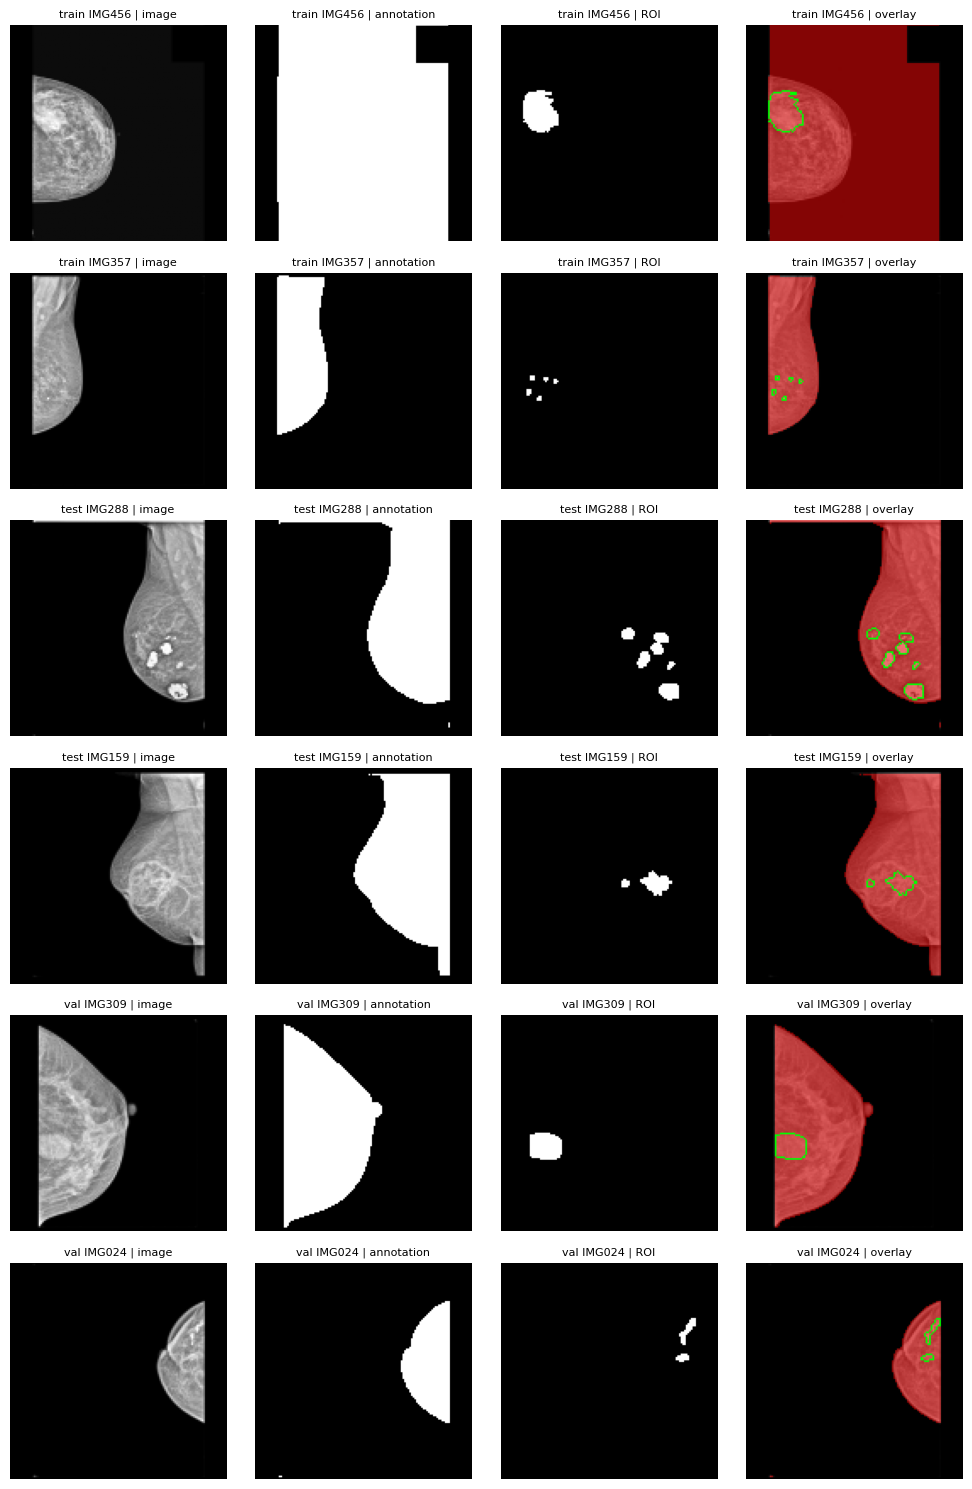

In [ ]:
# d) look at them: image | annotation | ROI | overlay
rng = np.random.default_rng(0)
fig, ax = plt.subplots(6, 4, figsize=(10, 15))
for r, s in enumerate(['train', 'train', 'test', 'test', 'val', 'val']):
    i = rng.choice(splits[s]); img, pix, roi = data[i]
    ov = np.stack([img] * 3, -1).copy()
    ov[pix > 0] = (0.5 * ov[pix > 0] + 0.5 * np.array([255, 0, 0])).astype(np.uint8)
    cnt, _ = cv2.findContours(roi, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE); cv2.drawContours(ov, cnt, -1, (0, 255, 0), 1)
    for c, (a, t) in enumerate([(img, 'image'), (pix, 'annotation'), (roi, 'ROI'), (ov, 'overlay')]):
        ax[r, c].imshow(a, cmap='gray'); ax[r, c].set_title(f'{s} {i} | {t}', fontsize=8); ax[r, c].axis('off')
plt.tight_layout(); plt.show()

## 7. Copy to Google Drive

In [ ]:
DRIVE_OUT.parent.mkdir(parents=True, exist_ok=True)
if DRIVE_OUT.exists(): shutil.rmtree(DRIVE_OUT)
shutil.copytree(OUT_DIR, DRIVE_OUT)
print('Saved to', DRIVE_OUT)

Saved to /content/drive/MyDrive/breast-cancer-segmentation/data/DMID_128_2


## 8. Interactive EDA viewer (for slides or sharing)

Creates one self-contained HTML file (works offline): summary numbers, key findings, interactive charts (hover for details, click a dot to open that case) and a browser to flip through image / lesion / ROI overlays. Open it in any browser, or screenshot charts for slides.

In [ ]:
VIEWER_TEMPLATE = r'''<!doctype html>
<html lang="en"><head><meta charset="utf-8"><meta name="viewport" content="width=device-width,initial-scale=1">
<title>DMID EDA Viewer</title>
<style>
:root{--bg:#fafaf9;--card:#fff;--ink:#1c1917;--mute:#78716c;--line:#e7e5e4;--train:#2563eb;--test:#d97706;--val:#059669;--acc:#2563eb}
@media (prefers-color-scheme:dark){:root:not([data-theme=light]){--bg:#13110f;--card:#1c1917;--ink:#f5f5f4;--mute:#a8a29e;--line:#2e2a27;--train:#60a5fa;--test:#fbbf24;--val:#34d399;--acc:#60a5fa}}
:root[data-theme=dark]{--bg:#13110f;--card:#1c1917;--ink:#f5f5f4;--mute:#a8a29e;--line:#2e2a27;--train:#60a5fa;--test:#fbbf24;--val:#34d399;--acc:#60a5fa}
*{box-sizing:border-box}body{margin:0;background:var(--bg);color:var(--ink);font:15px/1.5 system-ui,-apple-system,Segoe UI,sans-serif}
.wrap{max-width:1180px;margin:0 auto;padding:24px 16px 56px}
h1{font-size:26px;margin:0 0 4px}h2{font-size:17px;margin:0 0 4px}p.sub{color:var(--mute);margin:0 0 20px}
.grid{display:grid;gap:16px}.kpis{grid-template-columns:repeat(auto-fit,minmax(150px,1fr));margin-bottom:16px}
.card{background:var(--card);border:1px solid var(--line);border-radius:12px;padding:16px}
.kpi b{display:block;font-size:28px;line-height:1.1}.kpi span{color:var(--mute);font-size:13px}
.two{grid-template-columns:repeat(auto-fit,minmax(340px,1fr))}
.note{color:var(--mute);font-size:13px;margin:0 0 8px}
svg{width:100%;height:auto;display:block;overflow:visible}svg text{fill:var(--mute);font-size:11px}
.tip{position:fixed;pointer-events:none;background:var(--ink);color:var(--bg);padding:6px 9px;border-radius:6px;font-size:12px;display:none;z-index:9;max-width:240px}
.legend{display:flex;gap:14px;font-size:13px;margin:4px 0 6px;flex-wrap:wrap}.legend i{display:inline-block;width:10px;height:10px;border-radius:2px;margin-right:5px}
ul.find{margin:0;padding-left:18px}ul.find li{margin:4px 0}
.viewer{display:grid;grid-template-columns:1fr;gap:12px}
.ctrl{display:flex;flex-wrap:wrap;gap:10px;align-items:center}
select,input[type=text],button{font:inherit;padding:6px 10px;border:1px solid var(--line);background:var(--card);color:var(--ink);border-radius:8px}
button{cursor:pointer}button:hover{border-color:var(--acc)}
.panels{display:grid;grid-template-columns:repeat(auto-fit,minmax(200px,1fr));gap:12px}
.panels figure{margin:0;text-align:center}.panels canvas{width:100%;max-width:300px;aspect-ratio:1;image-rendering:pixelated;border-radius:8px;background:#000}
figcaption{font-size:12px;color:var(--mute);margin-top:4px}
.meta{font-size:13px;color:var(--mute)}label{font-size:13px;color:var(--mute)}
</style></head><body><div class="wrap">
<h1>DMID breast-cancer segmentation — EDA viewer</h1>
<p class="sub">Preprocessed 128×128 dataset · hover charts for details · click a point to open that case below</p>
<div class="grid kpis" id="kpis"></div>
<div class="card" style="margin-bottom:16px"><h2>Key findings</h2><ul class="find" id="find"></ul></div>
<div class="grid two">
  <div class="card"><h2>Dataset coverage</h2><p class="note">Only annotated images can be used for supervised training.</p><div id="c_cov"></div></div>
  <div class="card"><h2>Train / test / val split</h2><p class="note">Each case's image, annotation and ROI stay in the same split.</p><div id="c_split"></div></div>
  <div class="card"><h2>Lesion size distribution</h2><p class="note">Share of the 128×128 image covered by the lesion annotation.</p><div class="legend" id="lg1"></div><div id="c_hist"></div></div>
  <div class="card"><h2>Lesion vs ROI area</h2><p class="note">Each dot is one case. ROI should always be at least as large as the lesion.</p><div class="legend" id="lg2"></div><div id="c_sc"></div></div>
  <div class="card"><h2>Original image sizes</h2><p class="note">Pixels before resizing. Different scanners/crops give different sizes.</p><div class="legend" id="lg3"></div><div id="c_size"></div></div>
  <div class="card"><h2>Image brightness</h2><p class="note">Mean grey level per 128×128 image.</p><div class="legend" id="lg4"></div><div id="c_int"></div></div>
</div>
<div class="card" style="margin-top:16px"><h2>Case browser</h2>
<div class="viewer">
 <div class="ctrl">
  <select id="fsplit"><option value="all">All splits</option><option>train</option><option>test</option><option>val</option></select>
  <button id="prev">◀</button><input type="range" id="sl" min="0" max="0" value="0" style="flex:1;min-width:140px"><button id="next">▶</button>
  <input type="text" id="find_id" placeholder="Case id e.g. IMG008" size="14">
  <label><input type="checkbox" id="t_pix" checked> lesion</label>
  <label><input type="checkbox" id="t_roi" checked> ROI outline</label>
 </div>
 <div class="meta" id="meta"></div>
 <div class="panels">
  <figure><canvas id="cv0" width="128" height="128"></canvas><figcaption>Image</figcaption></figure>
  <figure><canvas id="cv1" width="128" height="128"></canvas><figcaption>Overlay (red lesion, green ROI)</figcaption></figure>
  <figure><canvas id="cv2" width="128" height="128"></canvas><figcaption>Lesion annotation mask</figcaption></figure>
  <figure><canvas id="cv3" width="128" height="128"></canvas><figcaption>ROI mask</figcaption></figure>
 </div></div></div>
</div><div class="tip" id="tip"></div>
<script>
const D=__DATA__;const C=D.cases,S=['train','test','val'];
const col=s=>getComputedStyle(document.documentElement).getPropertyValue('--'+s).trim();
const $=id=>document.getElementById(id),tip=$('tip');
const fmt=(x,d=1)=>x.toFixed(d),pct=x=>fmt(x*100,1)+'%';
const med=a=>{const s=[...a].sort((x,y)=>x-y);return s[Math.floor(s.length/2)]};
const mean=a=>a.reduce((x,y)=>x+y,0)/a.length;
function showTip(e,h){tip.innerHTML=h;tip.style.display='block';tip.style.left=Math.min(e.clientX+12,innerWidth-250)+'px';tip.style.top=(e.clientY+12)+'px'}
function hideTip(){tip.style.display='none'}
const NS='http://www.w3.org/2000/svg';
function el(p,t,a,h){const e=document.createElementNS(NS,t);for(const k in a)e.setAttribute(k,a[k]);if(h!=null)e.textContent=h;p.appendChild(e);return e}
function mk(id,W=520,H=260){const r=$(id);r.innerHTML='';return el(r,'svg',{viewBox:`0 0 ${W} ${H}`})}
function legend(id){$(id).innerHTML=S.map(s=>`<span><i style="background:${col(s)}"></i>${s} (${C.filter(c=>c.split===s).length})</span>`).join('')}
const M={l:48,r:12,t:10,b:34};
const nt=(v,int)=>int||Math.abs(v)>=20?Math.round(v):+v.toFixed(2);
function axes(svg,W,H,x0,x1,y0,y1,xl,yl,xt=5,yt=5){
  const iw=W-M.l-M.r,ih=H-M.t-M.b,X=v=>M.l+(v-x0)/(x1-x0)*iw,Y=v=>M.t+ih-(v-y0)/(y1-y0)*ih;
  for(let i=0;i<=yt;i++){const v=y0+(y1-y0)*i/yt;el(svg,'line',{x1:M.l,x2:W-M.r,y1:Y(v),y2:Y(v),stroke:col('line')});el(svg,'text',{x:M.l-6,y:Y(v)+4,'text-anchor':'end'},nt(v,yl==='cases'))}
  for(let i=0;i<=xt;i++){const v=x0+(x1-x0)*i/xt;el(svg,'text',{x:X(v),y:H-M.b+15,'text-anchor':'middle'},nt(v,false))}
  el(svg,'text',{x:M.l+iw/2,y:H-2,'text-anchor':'middle'},xl);
  const t=el(svg,'text',{x:12,y:M.t+ih/2,'text-anchor':'middle',transform:`rotate(-90 12 ${M.t+ih/2})`},yl);
  return {X,Y,iw,ih}}
function hbars(id,rows){const W=520,rh=44,H=rows.length*rh+10,svg=mk(id,W,H),mx=Math.max(...rows.map(r=>r.v));
  rows.forEach((r,i)=>{const y=i*rh+6,w=(W-170)*r.v/mx;el(svg,'text',{x:0,y:y+21,style:'font-size:14px'},r.k);
   const b=el(svg,'rect',{x:140,y,width:w,height:30,rx:5,fill:r.c});el(svg,'text',{x:146+w,y:y+20,style:'fill:var(--ink);font-weight:600;font-size:15px'},r.v+(r.s?' · '+r.s:''));
   b.onmousemove=e=>showTip(e,r.t||r.k+': '+r.v);b.onmouseleave=hideTip})}
function hist(id,vals,bins,xl,logx){const W=520,H=260,svg=mk(id,W,H);
  const all=C.map(vals),lo=Math.min(...all),hi=Math.max(...all),f=logx?Math.log10:(v=>v),inv=logx?(v=>Math.pow(10,v)):(v=>v);
  const a=f(Math.max(lo,1e-6)),b=f(hi),bw=(b-a)/bins||1,cnt={};S.forEach(s=>cnt[s]=Array(bins).fill(0));
  C.forEach(c=>{let i=Math.min(bins-1,Math.floor((f(Math.max(vals(c),1e-6))-a)/bw));cnt[c.split][i]++});
  const my=Math.max(...S.flatMap(s=>cnt[s]),1),ax=axes(svg,W,H,a,b,0,my,xl+(logx?' (log scale)':''),'cases',5,Math.min(my,5));
  svg.querySelectorAll('text').forEach(t=>{if(logx&&t.getAttribute('text-anchor')==='middle'&&!t.getAttribute('transform')&&+t.textContent&&t.getAttribute('y')>H-M.b+10&&t.textContent.indexOf(' ')<0)t.textContent=fmt(inv(+t.textContent),inv(+t.textContent)<1?2:1)});
  const bwid=ax.iw/bins/3;
  S.forEach((s,k)=>cnt[s].forEach((n,i)=>{if(!n)return;const x=ax.X(a+i*bw)+k*bwid+1;
   const r=el(svg,'rect',{x,y:ax.Y(n),width:Math.max(bwid-1,1),height:M.t+ax.ih-ax.Y(n),fill:col(s),rx:2});
   r.onmousemove=e=>showTip(e,`<b>${s}</b>: ${n} cases<br>${xl}: ${fmt(inv(a+i*bw),2)} – ${fmt(inv(a+(i+1)*bw),2)}`);r.onmouseleave=hideTip}))}
function scatter(id,fx,fy,xl,yl,diag,fmtx=v=>v,fmty=v=>v){const W=520,H=260,svg=mk(id,W,H);
  const xs=C.map(fx),ys=C.map(fy),x1=Math.max(...xs)*1.05,y1=Math.max(...ys)*1.05,x0=Math.min(0,...xs),y0=Math.min(0,...ys);
  const ax=axes(svg,W,H,diag?0:x0,diag?Math.max(x1,y1):x1,diag?0:y0,diag?Math.max(x1,y1):y1,xl,yl);
  if(diag)el(svg,'line',{x1:ax.X(0),y1:ax.Y(0),x2:ax.X(Math.max(x1,y1)),y2:ax.Y(Math.max(x1,y1)),stroke:col('mute'),'stroke-dasharray':'4 3'});
  C.forEach(c=>{const p=el(svg,'circle',{cx:ax.X(fx(c)),cy:ax.Y(fy(c)),r:4,fill:col(c.split),'fill-opacity':.65,stroke:col(c.split),style:'cursor:pointer'});
   p.onmousemove=e=>showTip(e,`<b>${c.id}</b> (${c.split})<br>${xl}: ${fmtx(fx(c))}<br>${yl}: ${fmty(fy(c))}<br><i>click to open</i>`);p.onmouseleave=hideTip;p.onclick=()=>openCase(c.id)})}
// ---------- summary
const n=C.length,pf=C.map(c=>c.pix_frac),sizes=new Set(C.map(c=>c.orig_h+'x'+c.orig_w)).size;
const outside=C.filter(c=>c.pix_outside_roi).length,tiny=C.filter(c=>c.pix_frac<0.002).length,vanish=C.filter(c=>c.pix_frac===0).length;
const mism=C.filter(c=>c.size_mismatch).length;
const kp=[[D.total_unique??'–','unique images'],[n,'annotated cases used'],[S.map(s=>C.filter(c=>c.split===s).length).join(' / '),'train / test / val'],[pct(mean(pf)),'mean lesion share of image'],[sizes,'distinct original sizes']];
$('kpis').innerHTML=kp.map(k=>`<div class="card kpi"><b>${k[0]}</b><span>${k[1]}</span></div>`).join('');
const F=[];
if(D.total_unique)F.push(`<b>${n} of ${D.total_unique} images (${pct(n/D.total_unique)}) have annotations</b>; the other ${D.total_unique-n} are unlabelled and not used for supervised training.`);
F.push(`<b>Lesions are small:</b> median ${pct(med(pf))} of the image (mean ${pct(mean(pf))}). About ${pct(1-mean(pf))} of pixels are background, so plain pixel accuracy is misleading. Prefer Dice / IoU and a Dice, Focal or Tversky loss.`);
if(tiny)F.push(`<b>${tiny} case(s) have a lesion under 0.2% of the image</b> (a few pixels at 128×128). These are easily lost by downsampling and are hard for the model.`);
if(vanish)F.push(`<b>${vanish} case(s) have an empty lesion mask after resizing.</b> Consider a larger size or cropping around the ROI.`);
F.push(`<b>Original images vary in size</b> (${sizes} distinct shapes, from ${Math.min(...C.map(c=>c.orig_w))} to ${Math.max(...C.map(c=>c.orig_w))} px wide), hence the resize step.`);
if(outside)F.push(`<b>${outside} case(s) have lesion pixels outside the ROI</b> at 128 px. Check them in the browser below.`);
else F.push('The lesion annotation lies inside the ROI in every case.');
if(mism)F.push(`${mism} case(s) had mask and image sizes that differed; masks were resized to the image first.`);
F.push(`Splits have similar lesion size: median lesion share ${S.map(s=>s+' '+pct(med(C.filter(c=>c.split===s).map(c=>c.pix_frac)))).join(', ')}.`);
$('find').innerHTML=F.map(x=>`<li>${x}</li>`).join('');
function draw(){
 ['lg1','lg2','lg3','lg4'].forEach(legend);
 const lab=D.total_unique?[{k:'Unique images',v:D.total_unique,c:col('mute')},{k:'Annotated (used)',v:n,c:col('train'),s:pct(n/D.total_unique)},{k:'Unlabelled',v:D.total_unique-n,c:col('line'),s:pct(1-n/D.total_unique)}]:[{k:'Annotated (used)',v:n,c:col('train')}];
 hbars('c_cov',lab);
 hbars('c_split',S.map(s=>{const k=C.filter(c=>c.split===s).length;return{k:s,v:k,c:col(s),s:pct(k/n)}}));
 hist('c_hist',c=>c.pix_frac*100,14,'lesion share of image (%)',true);
 scatter('c_sc',c=>c.pix_frac*100,c=>c.roi_frac*100,'lesion area (% of image)','ROI area (% of image)',true,v=>fmt(v,2)+'%',v=>fmt(v,2)+'%');
 scatter('c_size',c=>c.orig_w,c=>c.orig_h,'width (px)','height (px)',false);
 hist('c_int',c=>c.mean_int,14,'mean grey level (0–255)',false)}
draw();matchMedia('(prefers-color-scheme:dark)').addEventListener('change',draw);
// ---------- viewer
let list=C.slice(),idx=0;const imgCache={};
function loadImg(src){return imgCache[src]??(imgCache[src]=new Promise(r=>{const i=new Image();i.onload=()=>r(i);i.src=src}))}
function pixels(img){const c=document.createElement('canvas');c.width=c.height=128;const x=c.getContext('2d');x.drawImage(img,0,0);return x.getImageData(0,0,128,128)}
async function show(){
 const c=list[idx];if(!c)return;$('sl').max=list.length-1;$('sl').value=idx;
 $('meta').innerHTML=`<b style="color:var(--ink)">${c.id}</b> · ${c.split} · original ${c.orig_w}×${c.orig_h}px · lesion ${pct(c.pix_frac)} of image · ROI ${pct(c.roi_frac)} · case ${idx+1}/${list.length}`;
 const [I,P,R]=(await Promise.all([loadImg(c.img),loadImg(c.pix),loadImg(c.roi)])).map(pixels);
 const put=(id,fn)=>{const cv=$(id),x=cv.getContext('2d'),o=x.createImageData(128,128);for(let y=0;y<128;y++)for(let xx=0;xx<128;xx++){const p=(y*128+xx)*4;const v=fn(p,xx,y);o.data[p]=v[0];o.data[p+1]=v[1];o.data[p+2]=v[2];o.data[p+3]=255}x.putImageData(o,0,0)};
 const on=(d,x,y)=>x>=0&&y>=0&&x<128&&y<128&&d.data[(y*128+x)*4]>127;
 put('cv0',p=>[I.data[p],I.data[p],I.data[p]]);
 put('cv2',p=>[P.data[p],P.data[p],P.data[p]]);
 put('cv3',p=>[R.data[p],R.data[p],R.data[p]]);
 put('cv1',(p,x,y)=>{let v=[I.data[p],I.data[p],I.data[p]];
  if($('t_pix').checked&&P.data[p]>127)v=[v[0]*.45+255*.55,v[1]*.45,v[2]*.45];
  if($('t_roi').checked&&R.data[p]>127&&!(on(R,x-1,y)&&on(R,x+1,y)&&on(R,x,y-1)&&on(R,x,y+1)))v=[30,220,90];return v})}
function setList(){const f=$('fsplit').value;list=C.filter(c=>f==='all'||c.split===f);idx=0;show()}
function openCase(id){$('fsplit').value='all';list=C.slice();idx=Math.max(0,list.findIndex(c=>c.id===id));show();$('meta').scrollIntoView({behavior:'smooth',block:'center'})}
$('fsplit').onchange=setList;$('sl').oninput=e=>{idx=+e.target.value;show()};
$('prev').onclick=()=>{idx=(idx-1+list.length)%list.length;show()};$('next').onclick=()=>{idx=(idx+1)%list.length;show()};
$('t_pix').onchange=$('t_roi').onchange=show;
$('find_id').onchange=e=>{const q=e.target.value.trim().toUpperCase();const i=C.find(c=>c.id===q);if(i)openCase(q)};
addEventListener('keydown',e=>{if(e.target.tagName==='INPUT'&&e.target.type==='text')return;if(e.key==='ArrowRight')$('next').click();if(e.key==='ArrowLeft')$('prev').click()});
show();
</script></body></html>
'''

In [ ]:
import base64, json
import numpy as np, pandas as pd, cv2

def build_eda_viewer(out_dir, html_path, total_unique=None, template_path=None, template=None):
    out_dir = Path(out_dir)
    rep = pd.read_csv(out_dir / 'preprocessing_report2.csv')
    b64 = lambda p: 'data:image/png;base64,' + base64.b64encode(Path(p).read_bytes()).decode()
    cases = []
    for r in rep.sort_values(['split', 'id']).itertuples():
        d = out_dir / r.split
        img = cv2.imread(str(d / 'images' / f'{r.id}.png'), 0)
        pix = cv2.imread(str(d / 'masks' / f'{r.id}.png'), 0)
        roi = cv2.imread(str(d / 'roi_masks' / f'{r.id}.png'), 0)
        cases.append(dict(
            id=r.id, split=r.split, orig_h=int(r.orig_h), orig_w=int(r.orig_w),
            pix_frac=float((pix > 0).mean()), roi_frac=float((roi > 0).mean()),
            mean_int=float(img.mean()), pix_outside_roi=bool(((pix > 0) & (roi == 0)).any()),
            size_mismatch=bool(r.pix_size_mismatch or r.roi_size_mismatch),
            img=b64(d / 'images' / f'{r.id}.png'), pix=b64(d / 'masks' / f'{r.id}.png'), roi=b64(d / 'roi_masks' / f'{r.id}.png')))
    tpl = template if template is not None else Path(template_path).read_text()
    html = tpl.replace('__DATA__', json.dumps({'cases': cases, 'total_unique': total_unique}))
    Path(html_path).write_text(html)
    print(f'Saved {html_path}  ({Path(html_path).stat().st_size/1e6:.1f} MB, {len(cases)} cases)')

build_eda_viewer(OUT_DIR, OUT_DIR / 'dmid_eda_viewer.html', total_unique=len(image_by_id), template=VIEWER_TEMPLATE)
shutil.copy(OUT_DIR / 'dmid_eda_viewer.html', DRIVE_OUT.parent / 'dmid_eda_viewer.html')   # also keep a copy on Drive
from google.colab import files
files.download(str(OUT_DIR / 'dmid_eda_viewer.html'))


Saved /content/DMID_128_2/dmid_eda_viewer.html  (1.8 MB, 269 cases)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>